In [ ]:
########## LIBRERÍAS A UTILIZAR ##########
#Se importan la librerias a utilizar
import pandas as pd
from sklearn import datasets
import numpy as np
from collections import Counter
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

$\large\textbf{ARBOLES DE DECISIÓN}$

En esta sección se desarrollarán los modelos de ML Tree para comparar la predicción de la matrícula

$\large\textbf{5 MODELADO}$

    En esta sección se desarrollará el modelo de ML Treea predicción de la matrícula

In [ ]:
########## LIBRERÍAS A UTILIZAR ##########
#Se importan la librerias a utilizar
import pandas as pd
from sklearn.pipeline import Pipeline
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import sklearn.tree # Árboles de decisión
import sklearn.ensemble # Ensambles de modelos
import sklearn.model_selection
import sklearn.decomposition # Módulo donde encontramos el análisis de componentes principales
from sklearn import datasets
from collections import Counter

$\normalsize\textbf{5.1 Definición de Funciones}$

In [ ]:
##########DEFINICIÓN DE FUNCIONES #####
def calcula_metricas(nombre_algoritmo,y_test,y_pred):
### CLASE POSITIVA (1) ###
    #Calculo la precisión del modelo
    from sklearn.metrics import precision_score
    precision = precision_score(y_test, y_pred)

    #Calculo la exactitud del modelo
    from sklearn.metrics import accuracy_score
    exactitud = accuracy_score(y_test, y_pred)

    #Calculo la sensibilidad del modelo
    from sklearn.metrics import recall_score
    sensibilidad = recall_score(y_test, y_pred)

    #Calculo el Puntaje F1 del modelo
    from sklearn.metrics import f1_score
    puntajef1 = f1_score(y_test, y_pred)

    #Calculo la curva ROC - AUC del modelo
    from sklearn.metrics import roc_auc_score
    roc_auc = roc_auc_score(y_test, y_pred)

### CLASE NEGATIVA (0) ###
    from sklearn.metrics import confusion_matrix
    labels = [1, 0]
    cm = confusion_matrix(y_test, y_pred, labels = labels)
    tp,fn,fp,tn = cm.ravel()

    #True Negative Rate / specificity
    TNR_recall_espec = round(tn/(tn+fp),6)

    #Negative Predictive Value
    NPV_precision = round(tn/(tn+fn),6)

    #Cálculo del F1 para la clase negativa
    F1_neg = round(2 * (NPV_precision * TNR_recall_espec) / (NPV_precision + TNR_recall_espec),2)

    ## Vector de Desempeño - Resumen de Métricas del Modelo
    df_1 = pd.DataFrame({'Modelo': [nombre_algoritmo],'Clase ':[1],'Exactitud': [exactitud],'Precisión': [precision],
                   'Sensibilidad': [sensibilidad], 'F1': [puntajef1],'AUC': [roc_auc]})
    df_2 = pd.DataFrame({'Modelo': '','Clase ':[0],'Exactitud': '','Precisión': [NPV_precision],
                   'Sensibilidad': [TNR_recall_espec], 'F1': [F1_neg],'AUC': ''})
    df = pd.concat([df_1, df_2], ignore_index=True)

    return df
    #return df.style.hide_index()

In [ ]:
def matriz_confusion(y_test,y_pred):
    import matplotlib.pyplot as plt
    import seaborn as sns
    #Verifico la matriz de Confusión
    from sklearn.metrics import confusion_matrix
    matriz = confusion_matrix(y_test, y_pred,labels=[1, 0])

    ax = sns.heatmap(matriz, annot=True, cmap='Blues', fmt='g')
    ax.set_title('Matriz de Confusión\n\n');
    ax.set_xlabel('\nPredicción')
    ax.set_ylabel('Real ');

    ## Ticket labels - List must be in alphabetical order
    ax.xaxis.set_ticklabels(['True','False'])
    ax.yaxis.set_ticklabels(['True','False'])

    ## Display the visualization of the Confusion Matrix.
    plt.show()

In [ ]:
def importancia_variables(algoritmo, nombre_algoritmo):
    import matplotlib.pyplot as plt
    Importance = pd.DataFrame({'Importance':algoritmo.feature_importances_*100},
                          index = cols)


    Importance.sort_values(by = 'Importance',
                       axis = 0,
                       ascending = True).plot(kind = 'barh',
                                              color = 'steelblue', )
    plt.suptitle('Importancia de Variables')
    plt.title(nombre_algoritmo)

    plt.gca().legend_ = None

$\normalsize\textbf{5.2 Carga de datos}$

In [ ]:
#Carga de datos depurados
data = pd.read_excel("postulaciones_depurado.xlsx")
df2 = data.groupby(['ESTADO'])['ESTADO'].count()
df2

,ESTADO
ESTADO,
0,13365
1,3286


In [ ]:
# Separar las variables dependientes de la independientes
y = data['ESTADO'] #mi variable objetivo
X = data.drop(['ESTADO','PERIODO','IDPOS','SEXO','REGION','PACE'], axis = 1) #eliminamos estado porque es target, y eliminamos periodo y IDPOS por irrelevancia

#Captura los nombres de las variables independientes
cols = X.columns

#Cuenta la cantidad de registros por cada clase
Counter(y)

Counter({0: 13365, 1: 3286})

$\normalsize\textbf{5.3 Escalamientos de datos}$

In [ ]:
#Se escalan todos los datos por buena práctica, ya que los arboles de decisión no lo requieren
from sklearn.preprocessing import MinMaxScaler
escalar = MinMaxScaler()
X = escalar.fit_transform(X)

$\normalsize\textbf{5.4 Separación de datos Train/Test}$

In [ ]:
from sklearn.model_selection import train_test_split
#Separo los datos de "train" en entrenamiento y prueba para probar los algoritmos
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state = 0)

In [ ]:
#Cuenta la cantidad de registros por cada clase del set de entrenamiento
Counter(y_train)

Counter({0: 10704, 1: 2616})

$\normalsize\textbf{5.5 Arboles de Decisión}$

En esta sección se aplicará el entrenamiento y evaluación modelo DecisionTreeClasiffier para la predicción de la matrícula

$\textbf{Evaluación del modelo Decision Tree Classifier}$

In [ ]:
#Arboles de decisión
from sklearn.tree import DecisionTreeClassifier
tree_clf = DecisionTreeClassifier(max_depth=10, criterion = 'entropy') #profundidad y criterio de selección como entropy, por default este valor es gini

In [ ]:
#Entreno el modelo
tree_clf.fit(X_train, y_train)

DecisionTreeClassifier(criterion='entropy', max_depth=10)

In [ ]:
#Realizo una predicción
y_pred = tree_clf.predict(X_test)

In [ ]:
df = pd.DataFrame({'Predicción': y_pred, 'Real': y_test})
df.head(100)

,Predicción,Real
12601,0,0
7947,0,0
9840,0,0
1836,0,0
7660,0,0
...,...,...
8541,0,0
3948,1,0
663,0,0
11235,0,1


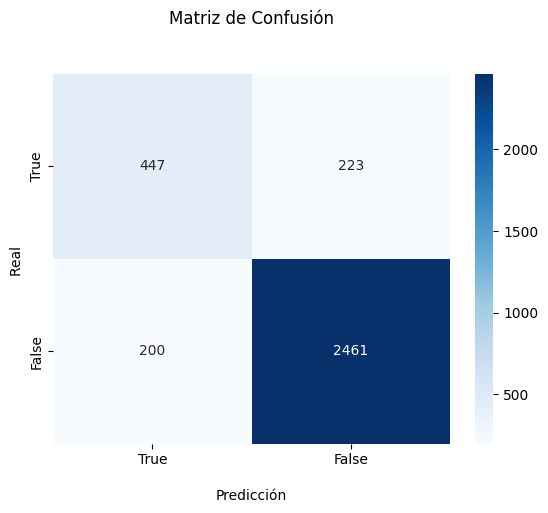

In [ ]:
#Calcula y despliega la matriz de confusión
matriz_confusion(y_test,y_pred)

In [ ]:
#Obtiene las métricas del modelo
df_metricas_tree = calcula_metricas('Tree',y_test,y_pred)
df_metricas_tree

,Modelo,Clase,Exactitud,Precisión,Sensibilidad,F1,AUC
0,Tree,1,0.873011,0.690881,0.667164,0.678815,0.796002
1,,0,,0.916915,0.924840,0.920000,


$\textbf{5.6 Importancia de las Variables}$

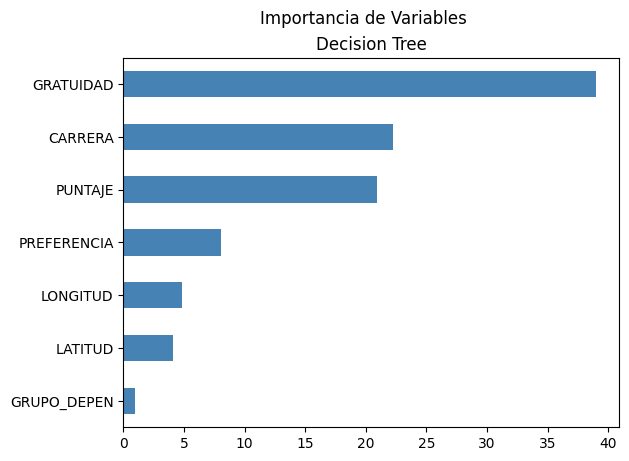

In [ ]:
#Calcula y despliega la importancia de las variables. con esta información podríamos ir eliminando variables que el modelo considera irrelevantes e ir experimentando
importancia_variables(tree_clf, "Decision Tree")

$\normalsize\textbf{5.7 Visualizar Árbol (opcional)}$

Instalar el ejecutable Graphviz desde
<a href="https://gitlab.com/api/v4/projects/4207231/packages/generic/graphviz-releases/2.50.0/windows_10_cmake_Release_graphviz-install-2.50.0-win64.exe">graphviz-2.50.0 (64-bit) EXE installer</a>

In [ ]:
import sklearn.tree as tree
import pydotplus
from six import StringIO
from IPython.display import Image
dot_data = StringIO()
tree.export_graphviz(tree_clf,
 out_file=dot_data,
 class_names=['0', '1'], # the target names. data.columns
 feature_names=data.drop(['ESTADO','PERIODO','IDPOS','SEXO','REGION','PACE'], axis = 1).columns, # the feature names.
 filled=True, # Whether to fill in the boxes with colours.
 rounded=True, # Whether to round the corners of the boxes.
 special_characters=True)
graph = pydotplus.graph_from_dot_data(dot_data.getvalue())
Image(graph.create_png())

Output hidden; open in https://colab.research.google.com to view.

el árbol está balanceado en altura pero desbalanceado en ancho (?
tiene más espectro de decisiones para decir que no, eso es porque los datos están desbalanceado, sino el nodo raíz debería estar por la mitad

In [ ]:
#!pip install pydotplus